In [4]:
from hydrogen import reconstruct_hydrogen
import astropy.units as u
from main_fip_bias_batch import process_hydrad_data
import matplotlib.pyplot as plt
import numpy as np

In [9]:
# root = "/Volumes/Crucial X9/collaborations/Biswajit/2026_Solphys/Hydrad_outputs2/Emax0.5"
root = "/Volumes/Crucial X9/Python_Script/fip_bias_hydrad/hydards/HYDRAD_flare_LL6e9_0.009_train_with_H_thermal_heating_2000s_1s_step_4_heatings"
history = reconstruct_hydrogen(
    root,
    mode="equilibrium",
    cache="results/hydrogen_validation/my_history.npz",
)


KeyboardInterrupt: 

In [24]:
import numpy as np
import astropy.units as u
from loop.reader import HydradReader
from loop.properties import LoopProperties
from wave.solver import WaveAnalyzer

root = "/Volumes/Crucial X9/collaborations/Biswajit/2026_Solphys/Hydrad_outputs2/Emax0.5"
strand = HydradReader(root, strand_num=30).read_strand()
props = LoopProperties(strand)
va = WaveAnalyzer(props).VA(props.s_array).to(u.cm / u.s).value

s = props.s_array.to(u.cm).value
T = props.T(props.s_array).to(u.K).value
va = WaveAnalyzer(props).VA(props.s_array).to(u.cm / u.s).value
dlnT = np.abs(np.gradient(np.log(T), s))
mid = len(s) // 2
i_left = np.argmax(dlnT[:mid])
i_right = mid + np.argmax(dlnT[mid:])
travel_time = np.trapezoid(1 / va[i_left:i_right + 1], s[i_left:i_right + 1])
frequency = (1 / (2 * travel_time)) * u.s**-1
print(frequency)


Loading from pydrad profile
0.024445628499344837 1 / s


/Volumes/Crucial X9/Python_Script/alfven_loop_SM_backup/loop/properties.py:16: UserWarning: No hydrogen populations in this HYDRAD profile. Using fully ionised hydrogen because ne = nH (Bradshaw & Cargill 2013).
  hydrogen_fraction, inferred = self.hydrogen_from_profile(input_file)


In [26]:
# input_file = '/Volumes/Crucial X9/Python_Script/fip_bias_hydrad/hydards/HYDRAD_flare_LL6e9_0.009_train_with_H_thermal_heating_2000s_1s_step_4_heatings'
input_file = "/Volumes/Crucial X9/collaborations/Biswajit/2026_Solphys/Hydrad_outputs2/Emax0.5"
for i in [0.206]:
    output_data = process_hydrad_data(
        input_file=input_file,
        frequency=i * u.s**-1,
        amplitude=0.97 * u.km / u.s,
        output_dir=input_file+'/fip_bias_output',
        strand_num=30,
        acoustic_flux=5e7 * u.erg / u.cm**2 / u.s,
        v_add=0.0 * u.km / u.s, 
    )


/Volumes/Crucial X9/Python_Script/alfven_loop_SM_backup/loop/properties.py:16: UserWarning: No hydrogen populations in this HYDRAD profile. Using fully ionised hydrogen because ne = nH (Bradshaw & Cargill 2013).
  hydrogen_fraction, inferred = self.hydrogen_from_profile(input_file)


Loading from pydrad profile
Solving ODE 
Function evaluations: 8533
Number of steps: 3613
ODE solved
Element: Ca, Atomic Number: 20, Mass Number: 40.078
Element: Mg, Atomic Number: 12, Mass Number: 24.304
Element: Fe, Atomic Number: 26, Mass Number: 55.845
Element: Si, Atomic Number: 14, Mass Number: 28.084
Element: S, Atomic Number: 16, Mass Number: 32.059
Element: C, Atomic Number: 6, Mass Number: 12.0096
Element: N, Atomic Number: 7, Mass Number: 14.0064
Element: O, Atomic Number: 8, Mass Number: 15.999
Element: Ne, Atomic Number: 10, Mass Number: 20.1797
Element: Ar, Atomic Number: 18, Mass Number: 39.948
Saved FIP bias vs height plot for 0.206_0.97_30: /Volumes/Crucial X9/collaborations/Biswajit/2026_Solphys/Hydrad_outputs2/Emax0.5/fip_bias_output/v_0.2060_A_0.97_F_5.0e07/images/fip_bias_vs_height_multi_0.206_0.97_30.png


In [27]:
def quantity_values(values, unit=None):
    """Return a NumPy array, converting Astropy quantities when present."""
    if hasattr(values, "to") and unit is not None:
        return np.asarray(values.to(unit).value)
    if hasattr(values, "value"):
        return np.asarray(values.value)
    return np.asarray(values)


def loop_distance_mm(data):
    return quantity_values(data["s_values"], u.Mm)


def plot_loop_atmosphere(data):
    s_mm = loop_distance_mm(data)
    temperature = quantity_values(data["T"], u.K)
    density = quantity_values(data["ne"], u.cm**-3)

    fig, ax_density = plt.subplots(figsize=(8, 4.8))
    ax_temperature = ax_density.twinx()

    ax_density.semilogy(s_mm, density, color="tab:blue", label="Electron density")
    ax_temperature.semilogy(s_mm, temperature, color="tab:red", label="Temperature")

    ax_density.set_xlabel("Distance along loop (Mm)")
    ax_density.set_ylabel("Electron density (cm$^{-3}$)", color="tab:blue")
    ax_temperature.set_ylabel("Temperature (K)", color="tab:red")
    ax_density.tick_params(axis="y", labelcolor="tab:blue")
    ax_temperature.tick_params(axis="y", labelcolor="tab:red")
    ax_density.set_title("HYDRAD atmosphere used by FIPpy")

    lines, labels = ax_density.get_legend_handles_labels()
    lines2, labels2 = ax_temperature.get_legend_handles_labels()
    ax_density.legend(lines + lines2, labels + labels2, loc="best")
    fig.tight_layout()
    return fig


def plot_ponderomotive_acceleration(data):
    s_mm = loop_distance_mm(data)
    acceleration = quantity_values(data["ponderomotive_acceleration"], u.cm / u.s**2)

    fig, ax = plt.subplots(figsize=(8, 4.5))
    ax.plot(s_mm, acceleration, color="black")
    ax.axhline(0.0, color="0.5", linewidth=0.8)
    ax.set_xlabel("Distance along loop (Mm)")
    ax.set_ylabel("Ponderomotive acceleration (cm s$^{-2}$)")
    ax.set_title("Ponderomotive acceleration along the loop")
    fig.tight_layout()
    return fig


def plot_ionisation_fractions(data, elements=("Ca", "Fe", "Mg", "Si", "O", "Ne", "Ar")):
    s_mm = loop_distance_mm(data)
    fractions = data["ionization_fractions"]

    fig, ax = plt.subplots(figsize=(8, 4.8))
    for element in elements:
        if element in fractions:
            ax.semilogy(s_mm, np.clip(fractions[element], 1e-6, 1.0), label=element)

    ax.set_xlabel("Distance along loop (Mm)")
    ax.set_ylabel("Ionisation fraction")
    ax.set_ylim(1e-4, 1.1)
    ax.set_title("Ionisation fractions used in the fractionation calculation")
    ax.legend(ncol=2)
    fig.tight_layout()
    return fig


def bias_arrays(data, element, side):
    segment = data["fip_bias_heights"].get(element, {}).get(side)
    if segment is None:
        return None, None
    heights = quantity_values(segment["heights"])
    bias = quantity_values(segment["bias"])
    return heights, bias


def plot_fip_bias_relative_to_oxygen(data, side="right", elements=("Ca", "Fe", "Mg", "Si", "S", "Ar", "Ne")):
    oxygen_height, oxygen_bias = bias_arrays(data, "O", side)
    if oxygen_height is None:
        raise KeyError(f"No oxygen FIP-bias data found for side={side!r}")

    fig, ax = plt.subplots(figsize=(8, 4.8))
    for element in elements:
        heights, bias = bias_arrays(data, element, side)
        if heights is None:
            continue
        oxygen_at_height = np.interp(heights, oxygen_height, oxygen_bias)
        ax.plot(heights, bias / oxygen_at_height, label=f"{element}/O")

    ax.axhline(1.0, color="0.5", linewidth=0.8)
    ax.set_xlabel("Height (Mm)")
    ax.set_ylabel("FIP bias normalized to O")
    ax.set_title(f"FIP bias at the {side} footpoint")
    ax.legend(ncol=2)
    fig.tight_layout()
    return fig

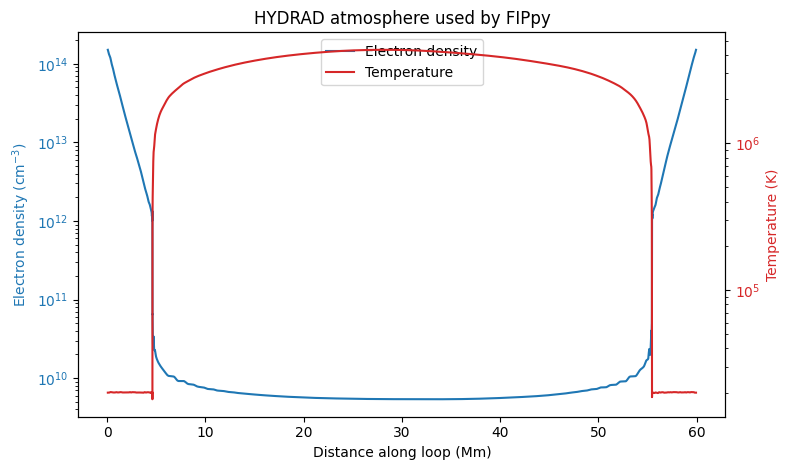

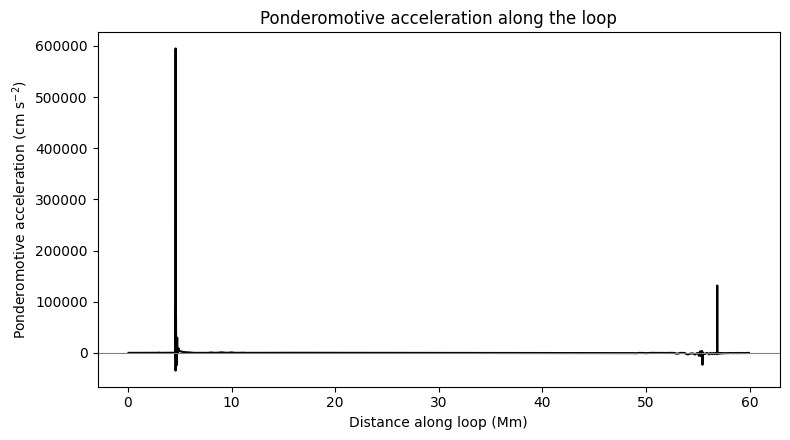

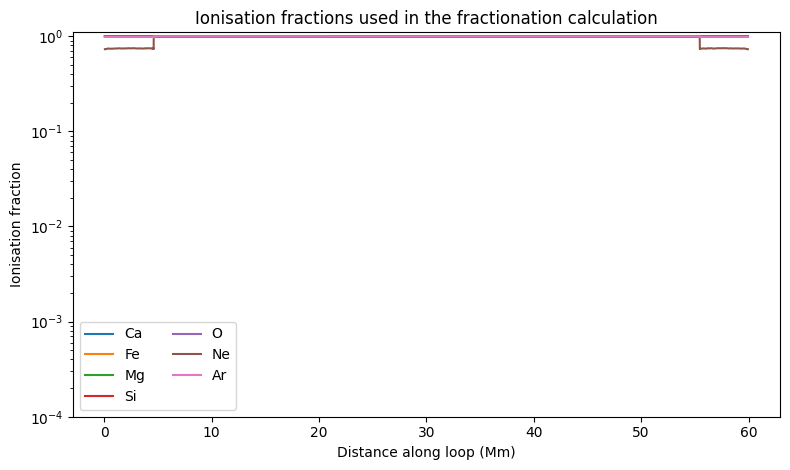

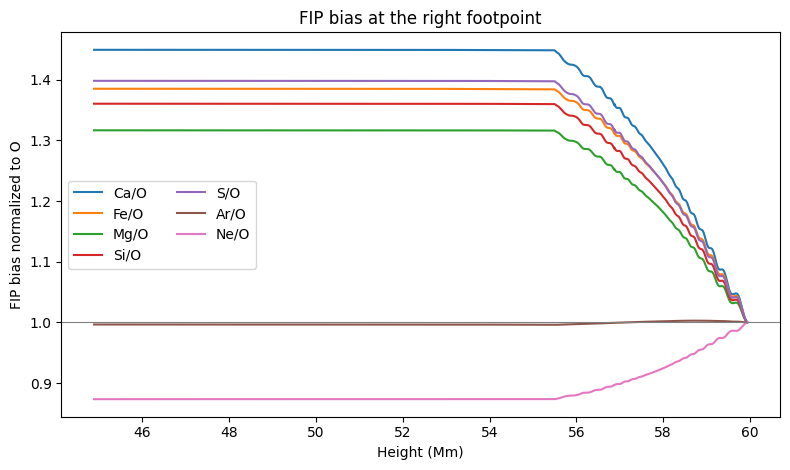

In [29]:
plot_loop_atmosphere(output_data)
plot_ponderomotive_acceleration(output_data)
plot_ionisation_fractions(output_data)
plot_fip_bias_relative_to_oxygen(output_data, side="right")
plt.show()